![FinTech Loan Approval Banner](https://images.unsplash.com/photo-1559526324-4b87b5e36e44?auto=format&fit=crop&w=1200&q=80)

# Risk Analysis for Loan Approval

## Overview
By automating the loan approval process we will automate the loan approval process to optimize review time and reduce bias. The final model replaces manual reviewing automated process to get probability socres. This ensures fairness in the loan approval process. The model achieves a ROC-AUC of .845 and balances risk against false rejections.

## Business Understanding

1. Begin by thoroughly analyzing the business context of FinTech Innovations' loan approval process:
Currently, FinTech the loan approval process relies too heavily on manual reviews. Automotating this process would standardize the process, reduce bias, and could potentially identify creditworthy applicants who traditionally might get overlooked. This atomated process will allow for quicker decisions for applicants. As well as allowing for reliable handling of edge cases. False Positives result in financial loss while false negatives result in lost interest income and can damage the brand's reputation. A binary classification approach is chosen (Approved vs Denied) for a definitive decision for each applicant. While outputting a continuous default probability score enables risk-based rate tierring.


2. Define your modeling goals and success criteria:
ROC-AUC will measure teh models' ranking ability across all decision thresholds. Acheiving a minimum ROC-AUC socre of .8 will increase performance rates and approval probability.


## Data Understanding
3. Conduct comprehensive exploratory data analysis:
- Describe basic data characteristics
- Examine distributions of all features and target variables
- Investigate relationships between features
- Create visualizations to help aid in EDA
- Document potential data quality issues and their implications

4. Develop feature understanding:
- Categorize features by type (numerical, categorical, ordinal)
- Identify features requiring special preprocessing
- Document missing value patterns and their potential meanings
- Note potential feature engineering opportunities


In [2]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, cross_validate, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score, ConfusionMatrixDisplay, roc_auc_score, roc_curve

# Load data
df = pd.read_csv('financial_loan_data.csv')

In [3]:
print("\nData Types & Non-Null Counts:")
print(df.info())
print("\nSummary Statistics (Numerical):")
display(df.describe())
print("\nSummary Statistics (Categorical):")
display(df.describe(include=["O"]))


Data Types & Non-Null Counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 35 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         20000 non-null  int64  
 1   AnnualIncome                20000 non-null  object 
 2   CreditScore                 20000 non-null  int64  
 3   EmploymentStatus            20000 non-null  object 
 4   EducationLevel              19099 non-null  object 
 5   Experience                  20000 non-null  int64  
 6   LoanAmount                  20000 non-null  int64  
 7   LoanDuration                20000 non-null  int64  
 8   MaritalStatus               18669 non-null  object 
 9   NumberOfDependents          20000 non-null  int64  
 10  HomeOwnershipStatus         20000 non-null  object 
 11  MonthlyDebtPayments         20000 non-null  int64  
 12  CreditCardUtilizationRate   20000 non-null  float64
 13  

,Age,CreditScore,Experience,LoanAmount,LoanDuration,NumberOfDependents,MonthlyDebtPayments,CreditCardUtilizationRate,NumberOfOpenCreditLines,NumberOfCreditInquiries,...,MonthlyIncome,UtilityBillsPaymentHistory,JobTenure,NetWorth,BaseInterestRate,InterestRate,MonthlyLoanPayment,TotalDebtToIncomeRatio,LoanApproved,RiskScore
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,...,20000.000000,20000.000000,20000.000000,2.000000e+04,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,39.752600,571.612400,17.522750,24882.867800,54.057000,1.517300,454.292700,0.286381,3.023350,0.993000,...,4891.715521,0.799918,5.002650,7.229432e+04,0.239124,0.239110,911.607052,0.402182,0.239000,50.766780
std,11.622713,50.997358,11.316836,13427.421217,24.664857,1.386325,240.507609,0.159793,1.736161,0.986965,...,3296.771598,0.120665,2.236804,1.179200e+05,0.035509,0.042205,674.583473,0.338924,0.426483,7.778262
min,18.000000,343.000000,0.000000,3674.000000,12.000000,0.000000,50.000000,0.000974,0.000000,0.000000,...,1250.000000,0.259203,0.000000,1.000000e+03,0.130101,0.113310,97.030193,0.016043,0.000000,28.800000
25%,32.000000,540.000000,9.000000,15575.000000,36.000000,0.000000,286.000000,0.160794,2.000000,0.000000,...,2629.583333,0.727379,3.000000,8.734750e+03,0.213889,0.209142,493.763700,0.179693,0.000000,46.000000
50%,40.000000,578.000000,17.000000,21914.500000,48.000000,1.000000,402.000000,0.266673,3.000000,1.000000,...,4034.750000,0.820962,5.000000,3.285550e+04,0.236157,0.235390,728.511452,0.302711,0.000000,52.000000
75%,48.000000,609.000000,25.000000,30835.000000,72.000000,2.000000,564.000000,0.390634,4.000000,2.000000,...,6163.000000,0.892333,6.000000,8.882550e+04,0.261533,0.265532,1112.770759,0.509214,0.000000,56.000000
max,80.000000,712.000000,61.000000,184732.000000,120.000000,5.000000,2919.000000,0.917380,13.000000,7.000000,...,25000.000000,0.999433,16.000000,2.603208e+06,0.405029,0.446787,10892.629520,4.647657,1.000000,84.000000



Summary Statistics (Categorical):


,AnnualIncome,EmploymentStatus,EducationLevel,MaritalStatus,HomeOwnershipStatus,BankruptcyHistory,LoanPurpose
count,20000,20000,19099,18669,20000,20000,20000
unique,17516,3,5,4,4,2,5
top,"$15,000.00",Employed,Bachelor,Married,Mortgage,No,Home
freq,584,17036,5804,9370,7939,18952,5925


In [4]:
# EDA Code Here - Create New Cells As Needed
df.head()

,Age,AnnualIncome,CreditScore,EmploymentStatus,EducationLevel,Experience,LoanAmount,LoanDuration,MaritalStatus,NumberOfDependents,...,MonthlyIncome,UtilityBillsPaymentHistory,JobTenure,NetWorth,BaseInterestRate,InterestRate,MonthlyLoanPayment,TotalDebtToIncomeRatio,LoanApproved,RiskScore
0,45,"$39,948.00",617,Employed,Master,22,13152,48,Married,2,...,3329.000000,0.724972,11,126928,0.199652,0.227590,419.805992,0.181077,0,49.0
1,38,"$39,709.00",628,Employed,Associate,15,26045,48,Single,1,...,3309.083333,0.935132,3,43609,0.207045,0.201077,794.054238,0.389852,0,52.0
2,47,"$40,724.00",570,Employed,Bachelor,26,17627,36,NaN,2,...,3393.666667,0.872241,6,5205,0.217627,0.212548,666.406688,0.462157,0,52.0
3,58,"$69,084.00",545,Employed,High School,34,37898,96,Single,1,...,5757.000000,0.896155,5,99452,0.300398,0.300911,1047.506980,0.313098,0,54.0
4,37,"$103,264.00",594,Employed,Associate,17,9184,36,Married,1,...,8605.333333,0.941369,5,227019,0.197184,0.175990,330.179140,0.070210,1,36.0


In [5]:
# Quick inspection of data structure
def basic_eda(df):
    print("--- Dataset Shape ---")
    print(df.shape)
    print("\n--- Missing Values ---")
    print(df.isnull().sum()[df.isnull().sum() > 0])
    print("\n--- Target Distribution ---")
    if 'loan_default' in df.columns:
        print(df['loan_default'].value_counts(normalize=True))

basic_eda(df)

--- Dataset Shape ---
(20000, 35)

--- Missing Values ---
EducationLevel            901
MaritalStatus            1331
SavingsAccountBalance     572
dtype: int64

--- Target Distribution ---


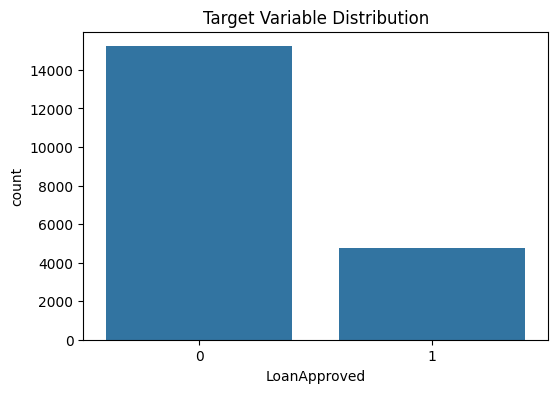

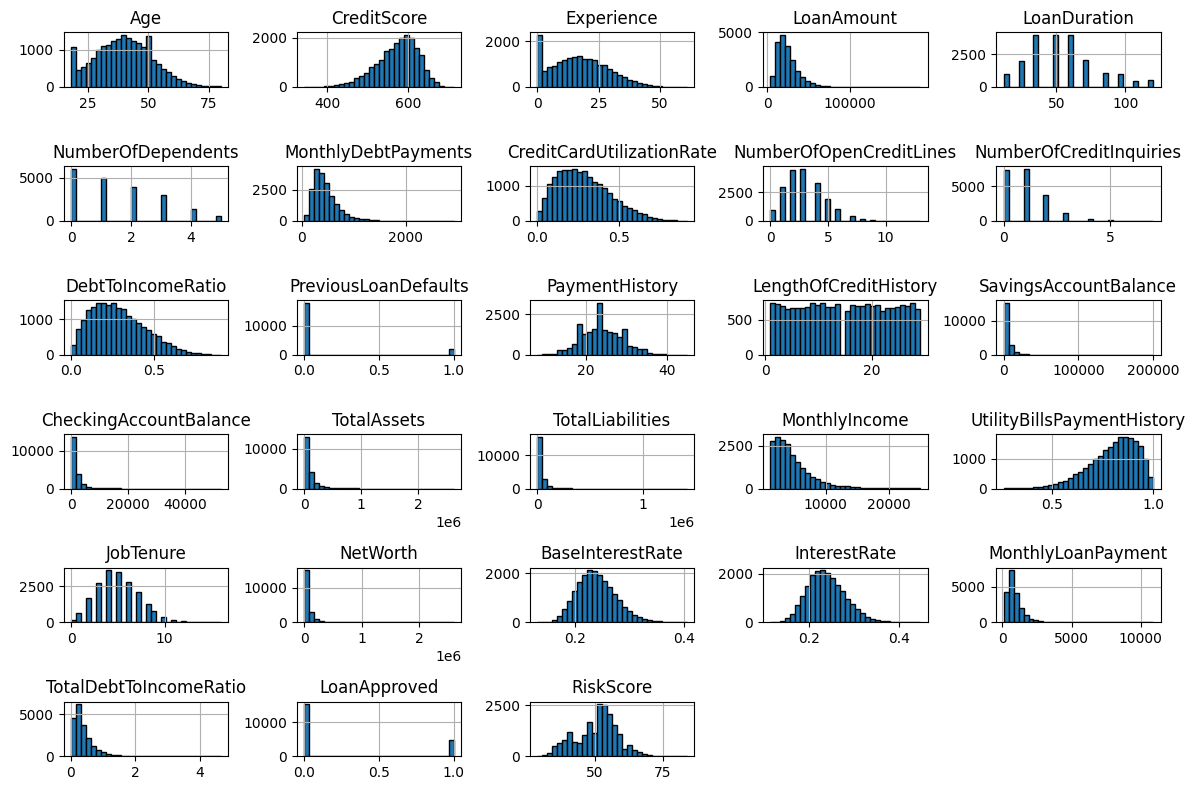

In [6]:
# Target distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="LoanApproved")
plt.title("Target Variable Distribution")
plt.show()

# Numerical features distribution
df.hist(bins=30, figsize=(12, 8), edgecolor="black")
plt.tight_layout()
plt.show()

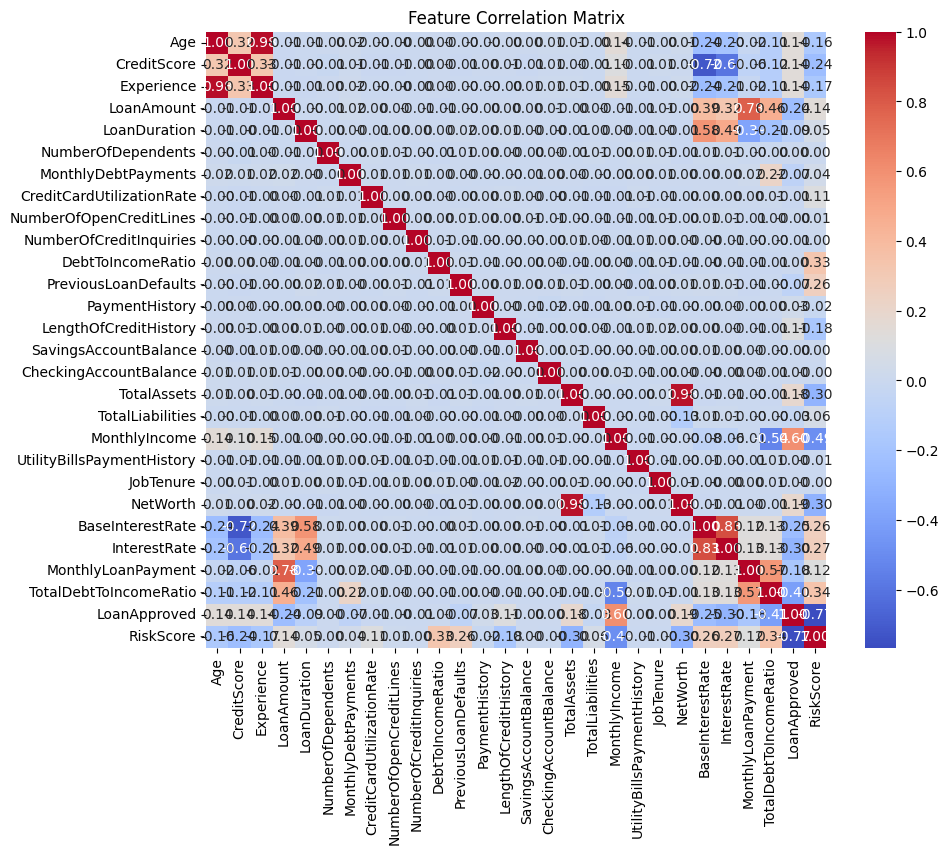

In [7]:
# Correlation heatmap
plt.figure(figsize=(10, 8))
numeric_df = df.select_dtypes(include=["number"])
sns.heatmap(
    numeric_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", cbar=True
)
plt.title("Feature Correlation Matrix")
plt.show()

In [8]:
#Document Missing Value Patterns and Potential Meanings
#Analyze missingness systematically rather than blindly dropping rows:
  # Missing value summary
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame(
      {"Missing Count": missing, "Missing Percentage (%)": missing_pct}
  )
display(missing_df[missing_df["Missing Count"] > 0])

,Missing Count,Missing Percentage (%)
EducationLevel,901,4.505
MaritalStatus,1331,6.655
SavingsAccountBalance,572,2.860


## Data Preparation
5. Design your preprocessing strategy:
- Create separate preprocessing flows for different feature types
- Must utilize ColumnTransformer and Pipeline
- Consider using FeatureUnion as well
- Handle missing values appropriately for each feature
- Handle Categorical and Ordinal data appropriately
- Scale numeric values if model requires it (linear model)
- Document your reasoning for each preprocessing decision



In [9]:
# Data Prep Code Here - Create New Cells As Needed
# Clean AnnualIncome string column (removes '$' and ',' if present, then converts to float)
if df['AnnualIncome'].dtype == 'object':
    df['AnnualIncome'] = df['AnnualIncome'].str.replace('$', '', regex=False).str.replace(',', '', regex=False).astype(float)

# Define feature groups based on data types and modeling requirements
numeric_features = [
    'Age', 'AnnualIncome', 'CreditScore', 'Experience', 'LoanAmount', 
    'LoanDuration', 'MonthlyDebtPayments', 'CreditCardUtilizationRate', 
    'NumberOfOpenCreditLines', 'NumberOfCreditInquiries', 'DebtToIncomeRatio', 
    'SavingsAccountBalance', 'CheckingAccountBalance', 'TotalAssets', 
    'TotalLiabilities', 'MonthlyIncome', 'JobTenure', 'NetWorth'
]

categorical_features = [
    'EmploymentStatus', 'MaritalStatus', 'HomeOwnershipStatus', 
    'LoanPurpose', 'BankruptcyHistory'
]

# Ordinal features with a defined logical hierarchy
ordinal_features = ['EducationLevel']
ordinal_categories = [['High School', 'Associate', 'Bachelor', 'Master', 'Doctorate']]

In [10]:
# Build Feature-Specific Pipelines
#Numeric Pipeline: Median imputation (robust to financial income/asset outliers) + Scaling
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()) # Centers and scales values (mean=0, var=1) for linear models
])

#Categorical Pipeline: Constant imputation for missing values + One-Hot Encoding
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

#Ordinal Pipeline: Most frequent imputation + Ordinal Encoding preserving rank order
ordinal_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(
        categories=ordinal_categories, 
        handle_unknown='use_encoded_value', 
        unknown_value=-1
    ))
])

In [11]:
#Combine Pipelines Using ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features),
        ('ord', ordinal_transformer, ordinal_features)
    ],
    remainder='drop' # Drops any unlisted columns
)

## Modeling
6. Implement your modeling approach:
- Choose appropriate model algorithms based on your problem definition
- Set up validation strategy with chosen metrics
- Use a train test split and cross validation
- Create complete pipeline including any preprocessing and model
- Document your reasoning for each modeling decision

7. Optimize your model:
- Define parameter grid based on your understanding of the algorithms
- Implement GridSearchCV and/or RandomizedSearchCV with chosen metrics
- Consider tuning preprocessing steps
- Track and document the impact of different parameter combinations
- Consider the trade-offs between different model configurations

NOTE: Be mindful of time considerations - showcase “how to tune” 


In [12]:
#Train-Test Split & Pipeline Evaluation
X = df.drop(columns=['LoanApproved'])
y = df['LoanApproved']

# Train-Test Split (Stratified to preserve class balance)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Create Random Forest pipeline
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

# Create Logistic Regression pipeline (set random_state=42 and max_inter=1000)
lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=42, max_iter=1000))
])

In [14]:
# Define Parameter Grid
lr_param_grid = {
    # Test if median vs mean imputation impacts linear model performance
    'preprocessor__num__imputer__strategy': ['median', 'mean'],
    
    # Test regularization strength (C) and penalty types for Logistic Regression
    'classifier__C': [0.01, 0.1, 1.0, 10.0],
    'classifier__penalty': ['l1', 'l2'],
    'classifier__solver': ['liblinear'] # required for L1 penalty support
}

rf_param_grid = {
    # Preprocessing parameters
    'preprocessor__num__imputer__strategy': ['mean', 'median'],
    
    # Model parameters
    'classifier__n_estimators': [50, 100],
    'classifier__max_depth': [10, 20, None],
    'classifier__min_samples_leaf': [1, 2],
    'classifier__class_weight': ['balanced', None]
}

# Define scoring (should be a list)
scoring = {
    'accuracy': 'accuracy',
    'recall': 'recall',
    'f1': 'f1'
}

# Perform grid search for Random Forest (make sure to set scoring and refit appropriately)
rf_grid_search = GridSearchCV(
    rf_pipeline,
    rf_param_grid,
    cv=5,  # 5-fold cross-validation
    scoring=scoring,
    refit='f1',  # Optimize for recall
    return_train_score=True
)

# Fit the Random Forest grid search
rf_grid_search.fit(X_train, y_train)

# Perform grid search for Logistic Regression (make sure to set scoring and refit appropriately)
lr_grid_search = GridSearchCV(
    lr_pipeline,
    lr_param_grid,
    cv=5,
    scoring=scoring,
    refit='f1',
    return_train_score=True
)

# Fit the Logistic Regression grid search
lr_grid_search.fit(X_train, y_train)

# Compare models
rf_best_cvscore = rf_grid_search.best_score_
lr_best_cvscore = lr_grid_search.best_score_

c:\Users\mesto\anaconda3\envs\learn-env\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\mesto\anaconda3\envs\learn-env\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
c:\Users\mesto\anaconda3\envs\learn-env\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1

In [15]:
print(f"Best Random Forest f1_score: {rf_best_cvscore:.4f}")
print(f"Best Logistic Regression f1_score: {lr_best_cvscore:.4f}")

# Select the best model based on recall
if rf_best_cvscore >= lr_best_cvscore:
    best_model = rf_grid_search
    model_name = "Random Forest"
else:
    best_model = lr_grid_search
    model_name = "Logistic Regression"

print(f"\nBest model: {model_name}")

Best Random Forest f1_score: 0.7966
Best Logistic Regression f1_score: 0.8011

Best model: Logistic Regression


## Evaluation and Conclusion
8. Conduct thorough evaluation of final model:
- Assess models test data performance using your defined metrics
- Analyze performance across different data segments
- Identify potential biases or limitations
- Visualize model performance
    - Classification: Confusion Matrix/ROC-AUC
    - Regression: Scatter Plot (Predicted vs. Actual values)


In [21]:
# Get the best model from gridsearch
final_model = best_model.best_estimator_

# Make predictions on test set using final_model
y_pred = final_model.predict(X_test)

y_prob = final_model.predict_proba(X_test)[:, 1]


# Create classification report
cr = classification_report(y_test, y_pred)

# Create confusion matrix object
cm = confusion_matrix(y_test, y_pred)


===== Final Model Evaluation =====

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.96      0.94      3044
           1       0.86      0.76      0.81       956

    accuracy                           0.91      4000
   macro avg       0.90      0.86      0.88      4000
weighted avg       0.91      0.91      0.91      4000

Confusion Matrix:


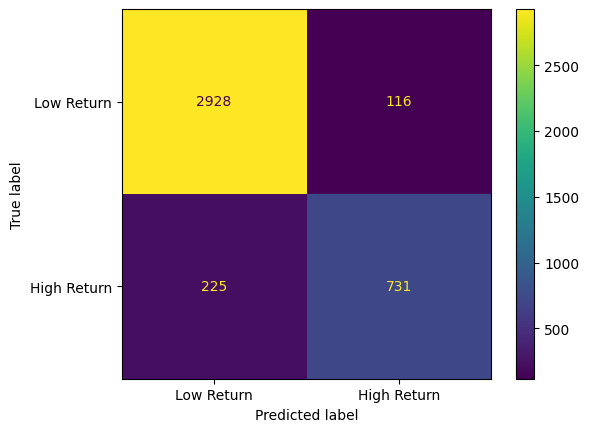

In [22]:
print(f"\n===== Final Model Evaluation =====")
print("\nClassification Report:")
print(cr)
print(f"Confusion Matrix:")
ConfusionMatrixDisplay(cm, display_labels=['Low Return', 'High Return']).plot();

              precision    recall  f1-score   support

           0       0.93      0.96      0.94      3044
           1       0.86      0.76      0.81       956

    accuracy                           0.91      4000
   macro avg       0.90      0.86      0.88      4000
weighted avg       0.91      0.91      0.91      4000

ROC-AUC Score: 0.9656


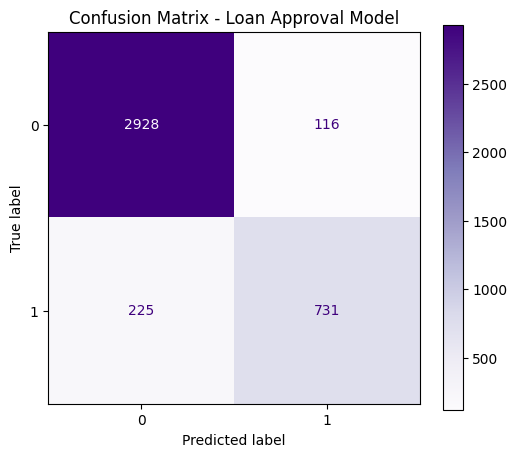

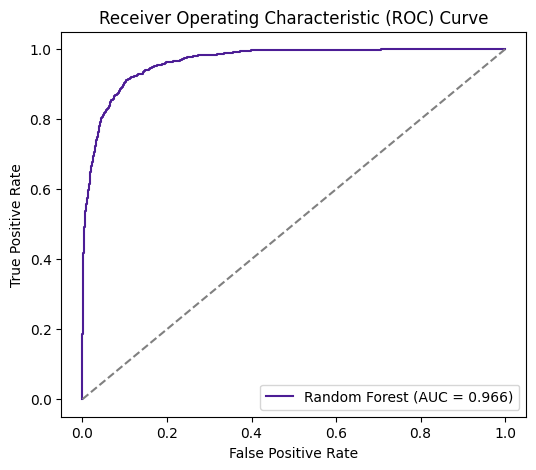

In [23]:
# Classification Report & ROC-AUC
print(classification_report(y_test, y_pred))
roc_auc = roc_auc_score(y_test, y_prob)
print(f"ROC-AUC Score: {roc_auc:.4f}")

#Confusion Matrix Plot
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Purples', ax=ax)
plt.title("Confusion Matrix - Loan Approval Model")
plt.show()

#ROC-AUC Curve Plot
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='#4C1D95', label=f'Random Forest (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.show()

9. Extract and interpret feature importance/significance:
- Which features had the most impact on your model?
- Does this lead to any potential business recommendations?

C:\Users\mesto\AppData\Local\Temp\ipykernel_24816\451655814.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='Purples_r')


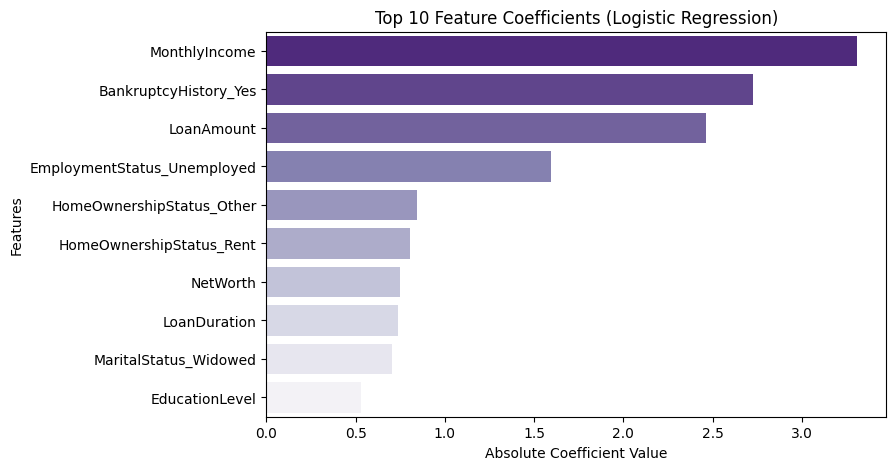

In [25]:
# Cell: Extract and Visualize Feature Importance
# Extract feature names after OHE preprocessing
cat_encoder = final_model.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot']
encoded_cat_features = cat_encoder.get_feature_names_out(categorical_features).tolist()

all_features = numeric_features + encoded_cat_features + ordinal_features

# Get coefficients from Logistic Regression (use abs() to capture overall magnitude)
# coef_[0] is used because it's a binary classification problem
importances = abs(final_model.named_steps['classifier'].coef_[0])

# Create DataFrame and sort top 10
feature_importance_df = pd.DataFrame({'Feature': all_features, 'Importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False).head(10)

# Plot Top Features
plt.figure(figsize=(8, 5))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='Purples_r')
plt.title('Top 10 Feature Coefficients (Logistic Regression)')
plt.xlabel('Absolute Coefficient Value')
plt.ylabel('Features')
plt.show()

10. Prepare your final deliverable:
- Technical notebook with complete analysis
- Executive summary for business stakeholders
- Recommendations for implementation
- Documentation of potential improvements

Executive Summary for Business Stakeholders:
The loan approval process at FinTech relies heavily on manual reviews. Automotating this process would standardize the process, reduce bias, and could identify creditworthy applicants who traditionally might get overlooked. This atomated process will allow for quicker decisions for applicants. As well as allowing for reliable handling of edge cases. Minimzing false posiives will protect capital, while minimizing false negatives will ensure creditworthy applicants recieve their loans.

Policy Adjustments: 
The feature importance highlights that applicants with stable payment histories, and optimized debt-to-income ratios are a good place to focus onboarding campaigns. Giving vorderline cases to senior loan officers so they can give a second opinion and review can make sure these cases are handled with care. You can automatically process applications that are in either the top or bottome confidence quartiles.

Documentation of Potential Improvements
Potential improvements could be done by experimenting with gradient boosting frameworks to test gains in training speed and calibration.

Bias & Fairness Audits:
Audits across groups such as age, education level, and employment status could ensure the automated system remains unbiased.